In [7]:
import json
import numpy as np
import matplotlib.pyplot as plt

from spectrogram import iq_to_spectrogram
from anomalies import add_tone, add_chirp, add_pulse, add_comb, add_ofdm, add_fsk

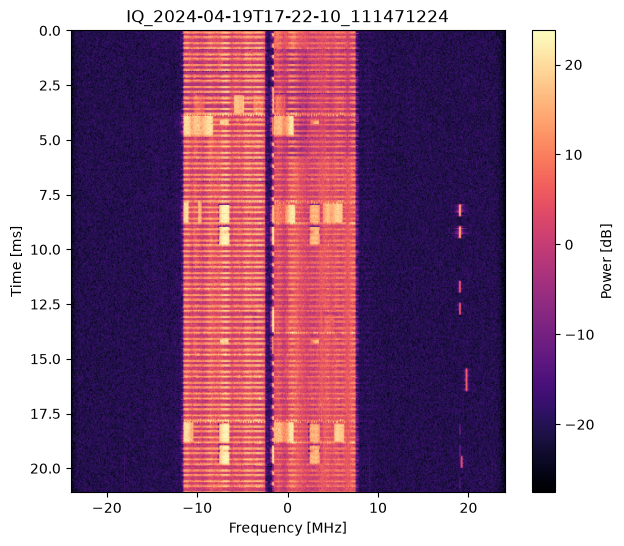

In [9]:
name = "IQ_2024-04-19T17-22-10_111471224"
path = "data/iq/" + name
fs = json.load(open(path + ".json"))["sampling_frequency"]  # 61.44 MHz

raw = np.fromfile(path + ".bin", dtype=np.int32)
iq = raw[0::2] + 1j * raw[1::2]

sxx_db, duration_ms = iq_to_spectrogram(iq, fs)

plt.figure(figsize=(7, 6))
plt.imshow(sxx_db, cmap="magma", aspect="auto", extent=[-24, 24, duration_ms, 0],
           vmin=np.percentile(sxx_db, 1), vmax=np.percentile(sxx_db, 99.9))
plt.xlabel("Frequency [MHz]")
plt.ylabel("Time [ms]")
plt.title(name)
plt.colorbar(label="Power [dB]")
plt.show()

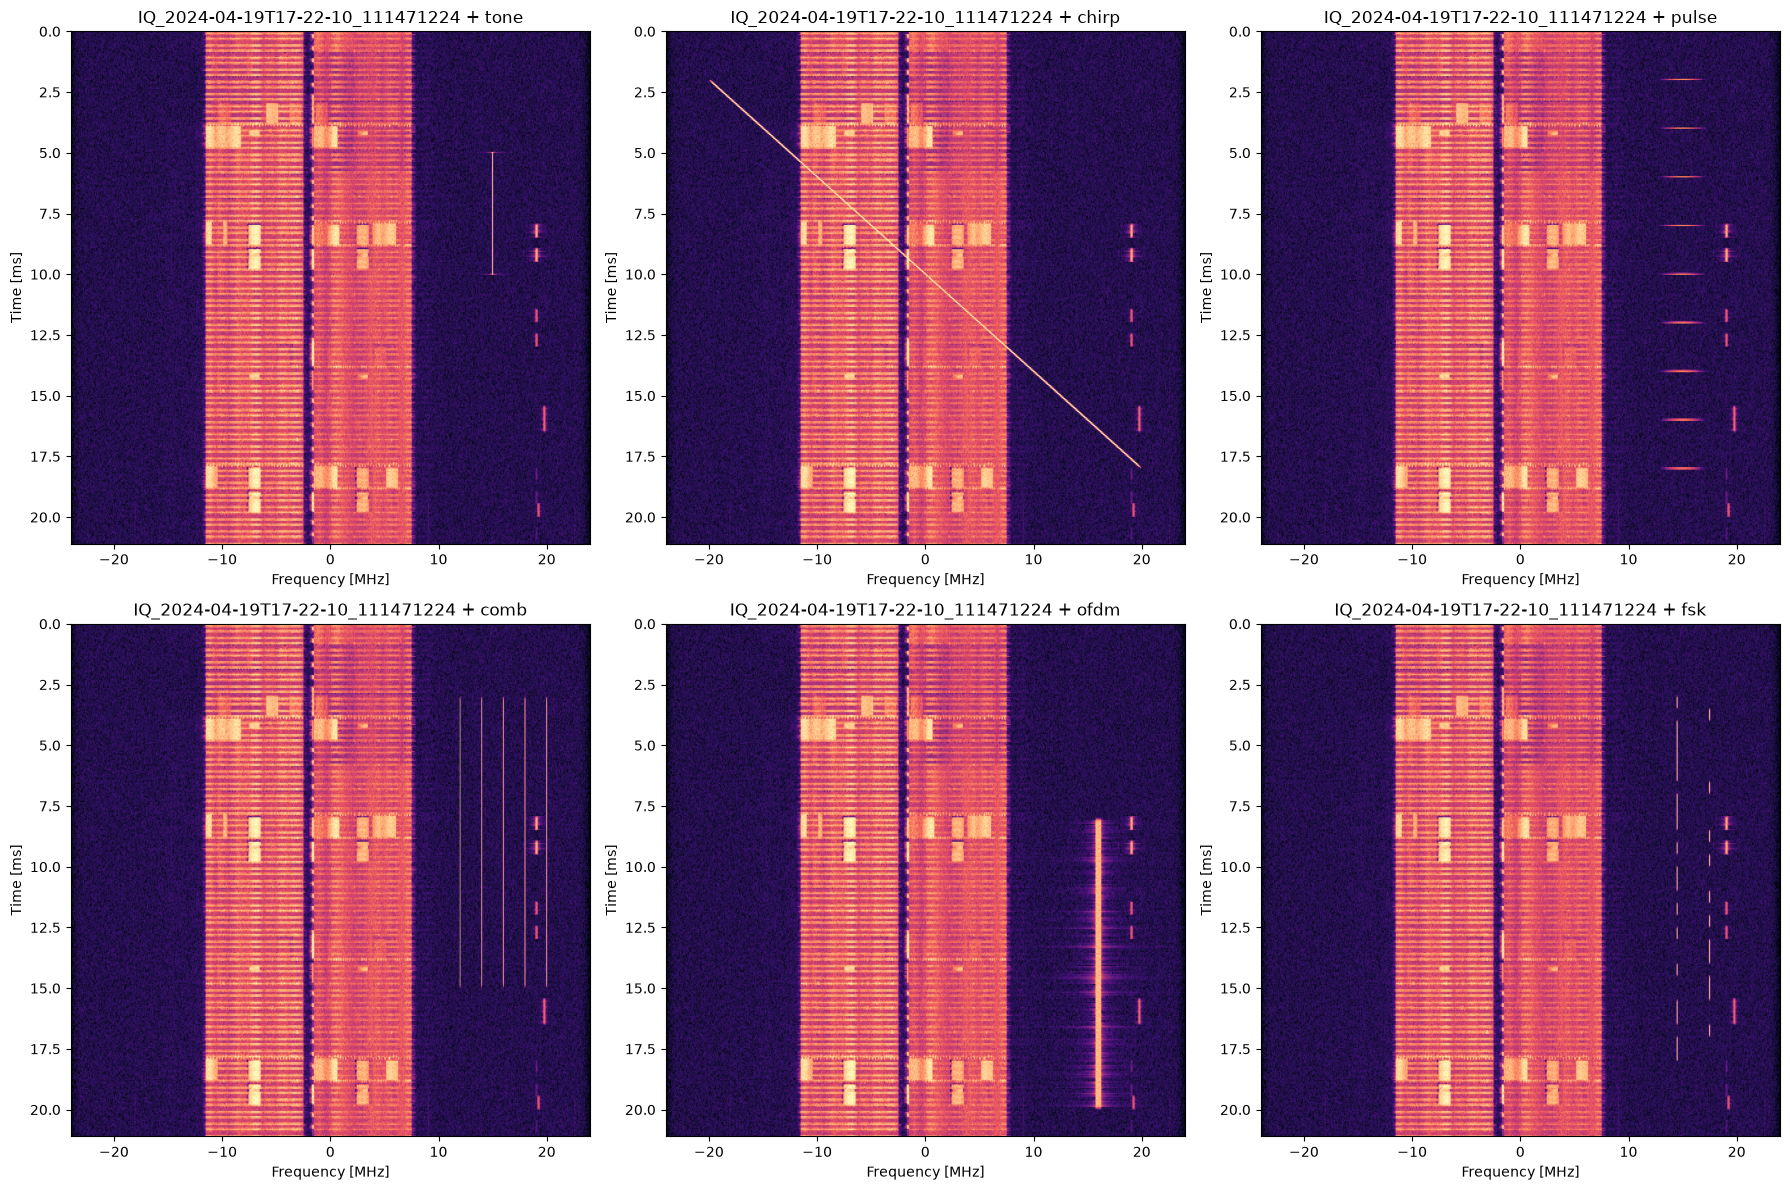

In [10]:
rng = np.random.default_rng(0)

examples = {
    "tone": add_tone(iq, fs, freq=15e6, start=5e-3, stop=10e-3, isr=-10, ramp=10e-10),
    "chirp": add_chirp(iq, fs, f_start=-20e6, f_stop=20e6, start=2e-3, stop=18e-3, isr=-10),
    "pulse": add_pulse(iq, fs, freq=15e6, start=2e-3, stop=20e-3, isr=10),
    "comb": add_comb(iq, fs, f_first=12e6, spacing=2e6, n_tones=5, start=3e-3, stop=15e-3, isr=-10),
    "ofdm": add_ofdm(iq, fs, freq=16e6, bandwidth=5e5, start=8e-3, stop=20e-3, isr=-10, rng=rng),
    "fsk": add_fsk(iq, fs, freq=16e6, deviation=1.5e6, symbol_duration=0.5e-3,
                   start=3e-3, stop=18e-3, isr=-10, rng=rng),
}

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, (kind, iq_anomaly) in zip(axes.ravel(), examples.items()):
    sxx_db, duration_ms = iq_to_spectrogram(iq_anomaly, fs)
    ax.imshow(sxx_db, cmap="magma", aspect="auto", extent=[-24, 24, duration_ms, 0],
              vmin=np.percentile(sxx_db, 1), vmax=np.percentile(sxx_db, 99.9))
    ax.set_xlabel("Frequency [MHz]")
    ax.set_ylabel("Time [ms]")
    ax.set_title(name + " + " + kind)
plt.tight_layout()
plt.show()

In [ ]:
from matplotlib.patches import Rectangle
from pipeline import load_config, generate_spectrogram

# Random anomalies with their labels; all random settings come from configs/v1.toml
cfg = load_config("configs/v1.toml")

fig, axes = plt.subplots(3, 2, figsize=(14, 18))
for seed, (ax_image, ax_mask) in enumerate(axes):
    sample = generate_spectrogram(path + ".bin", cfg, np.random.default_rng(seed))
    image, extent = sample["image_db"], [-24, 24, sample["duration_ms"], 0]

    # Left: spectrogram with the bounding box of every visible anomaly
    ax_image.imshow(image, cmap="magma", aspect="auto", extent=extent,
                    vmin=np.percentile(image, 1), vmax=np.percentile(image, 99.9))
    for a in sample["anomalies"]:
        if a["visible"]:
            width_mhz = (a["f_hi_hz"] - a["f_lo_hz"]) / 1e6
            height_ms = (a["t_end_s"] - a["t_start_s"]) * 1e3
            ax_image.add_patch(Rectangle((a["f_lo_hz"] / 1e6, a["t_start_s"] * 1e3), width_mhz,
                                         height_ms, fill=False, edgecolor="cyan"))
    ax_image.set_title(f"seed {seed}: " + ", ".join(
        f"{a['type']} {a['isr']:+.0f} dB" + ("" if a["visible"] else " (invisible)")
        for a in sample["anomalies"]))

    # Right: semantic mask, one colour per class, background black
    mask = np.ma.masked_equal(sample["semantic_mask"], 0)
    ax_mask.set_facecolor("black")
    ax_mask.imshow(mask, cmap="tab10", vmin=0, vmax=9, aspect="auto", extent=extent,
                   interpolation="nearest")
    ax_mask.set_title("semantic mask")
    for ax in (ax_image, ax_mask):
        ax.set_xlabel("Frequency [MHz]")
        ax.set_ylabel("Time [ms]")
plt.tight_layout()
plt.show()

sample["anomalies"]  # labels of the last example